# Tugas Akhir Modul 1 — Text Processing Pipeline
Nama : Eka Yuliana Rizky  
NIM  : 240306011  
Modul: Natural Language Processing — Modul 1

Notebook final ini menggabungkan konsep praktikum pertemuan 1–5 menggunakan Dataset Komentar TikTok Koperasi Desa Merah Putih. Dataset mentah yang diunggah berisi 220.051 baris dan 8 kolom. Kolom teks utama adalah `comment`; CSV tidak memiliki kolom label sentimen eksplisit.

Sumber Kaggle: 
https://www.kaggle.com/datasets/sinryurifal/dataset-komentar-tiktok-koperasi-desa-merah-putih

Pipeline mencakup eksplorasi corpus, cleaning, sentence segmentation, tokenisasi kata dan karakter, normalisasi, stopword removal, stemming, POS tagging, dependency parsing, n-gram, language model, visualisasi, analisis kesalahan, refleksi, dan kesimpulan.


# Persiapan — Library dan konfigurasi

In [1]:

import os
import re
import math
import string
import warnings
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.util import bigrams, trigrams
from IPython.display import display

for resource in ["punkt", "punkt_tab", "stopwords"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception as exc:
        print(f"Resource NLTK {resource} belum tersedia: {exc}")

pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Library inti siap digunakan.")


Library inti siap digunakan.


# 1. Dataset Description

In [3]:
dataset_description = {
    "Nama Dataset": "Dataset Komentar TikTok Koperasi Desa Merah Putih",
    "Sumber": "Kaggle — akun sinryurifal",
    "URL Kaggle": "https://www.kaggle.com/datasets/sinryurifal/dataset-komentar-tiktok-koperasi-desa-merah-putih",
    "Jumlah Data": "220.051 baris pada dataset mentah yang diunggah",
    "Jumlah Kolom": "8",
    "Kolom Teks": "comment",
    "Kolom Label": "Tidak tersedia / tidak terdeteksi",
    "Bahasa": "Bahasa Indonesia (berdasarkan isi komentar)",
    "Jenis Data": "Komentar TikTok / teks informal media sosial",
}
display(pd.DataFrame(dataset_description.items(), columns=["Aspek", "Keterangan"]))


,Aspek,Keterangan
0,Nama Dataset,Dataset Komentar TikTok Koperasi Desa Merah Putih
1,Sumber,Kaggle — akun sinryurifal
2,URL Kaggle,https://www.kaggle.com/datasets/sinryurifal/dataset-komentar-tiktok-koperasi-desa-merah-putih
3,Jumlah Data,220.051 baris pada dataset mentah yang diunggah
4,Jumlah Kolom,8
5,Kolom Teks,comment
6,Kolom Label,Tidak tersedia / tidak terdeteksi
7,Bahasa,Bahasa Indonesia (berdasarkan isi komentar)
8,Jenis Data,Komentar TikTok / teks informal media sosial


# 2. Load Dataset dan Corpus Exploration

In [6]:
candidate_paths = [
    Path("dataset/dataset.csv"),
    Path("dataset.csv"),
    Path("/mnt/data/dataset.csv"),
    Path("../dataset/dataset.csv"),
    Path("dataset_preprocessed.csv"),
    Path("/mnt/data/dataset_preprocessed(1).csv"),
    Path("output/dataset_preprocessed.csv"),
    Path("../dataset_preprocessed.csv"),
    Path("/mnt/data/dataset_preprocessed.csv"),
]
dataset_path = next((p for p in candidate_paths if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Simpan dataset.csv di folder dataset/ "
        "atau dataset_preprocessed.csv di folder output/ atau direktori notebook."
    )

df = pd.read_csv(dataset_path, low_memory=False)
print("File:", dataset_path.resolve())
print("Ukuran dataset (baris, kolom):", df.shape)
print("Jumlah kolom:", len(df.columns))
print("Nama kolom:", df.columns.tolist())
display(df.head())


File: C:\Users\acer\Documents\NLP\dataset.csv
Ukuran dataset (baris, kolom): (220051, 8)
Jumlah kolom: 8
Nama kolom: ['video_id', 'comment_id', 'parent_comment_id', 'level', 'username', 'nickname', 'comment', 'create_time']


,video_id,comment_id,parent_comment_id,level,username,nickname,comment,create_time
0,7.526460e+18,7.643300e+18,NaN,0.0,jbm123jayabetonmandiri,Christian sudartio,Beliau bilang untung nya 2 m ?,5/24/2026 10:58
1,7.526460e+18,7.643360e+18,7.643300e+18,1.0,sahrulmustakimm,sahrul,Makasih Mas,5/24/2026 14:47
2,7.526460e+18,7.643370e+18,7.643300e+18,1.0,jbm123jayabetonmandiri,Christian sudartio,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,5/24/2026 15:13
3,7.526460e+18,7.643370e+18,7.643300e+18,1.0,sahrulmustakimm,sahrul,[Sticker] dibilang Makasih Mas udah 2M itu,5/24/2026 15:35
4,7.526460e+18,7.643370e+18,7.643300e+18,1.0,jbm123jayabetonmandiri,Christian sudartio,😳😳😳,5/24/2026 15:12


In [8]:
# Deteksi kolom teks dan label secara konservatif
preferred_text_columns = ["comment", "text", "teks", "content", "review", "tweet", "komentar", "ulasan", "processed_text"]
TEXT_COLUMN = next((c for c in preferred_text_columns if c in df.columns), None)
if TEXT_COLUMN is None:
    object_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()
    if not object_columns:
        raise ValueError("Tidak ditemukan kolom teks. Periksa struktur dataset.")
    TEXT_COLUMN = object_columns[0]

label_candidates = ["label", "sentiment", "sentimen", "category", "kategori", "class", "kelas"]
LABEL_COLUMN = next((c for c in label_candidates if c in df.columns and c != TEXT_COLUMN), None)

print("Kolom teks yang dipakai:", TEXT_COLUMN)
print("Kolom label yang terdeteksi:", LABEL_COLUMN if LABEL_COLUMN else "Tidak terdeteksi")
print("Jumlah dokumen/baris awal:", len(df))
print("\nMissing value per kolom:")
display(df.isna().sum().rename("missing_value").to_frame())
print("Jumlah baris duplikat:", int(df.duplicated().sum()))
print("Jumlah teks duplikat:", int(df[TEXT_COLUMN].duplicated().sum()))


Kolom teks yang dipakai: comment
Kolom label yang terdeteksi: Tidak terdeteksi
Jumlah dokumen/baris awal: 220051

Missing value per kolom:


,missing_value
video_id,0
comment_id,0
parent_comment_id,185824
level,92912
username,0
nickname,22
comment,304
create_time,0


Jumlah baris duplikat: 61
Jumlah teks duplikat: 102236


# Statistik awal corpus
Dokumen kosong tidak dihitung sebagai teks yang dapat dianalisis. Duplikat diperiksa dan dilaporkan; penghapusan dilakukan pada salinan analisis agar dataset asli tidak ditimpa.

In [9]:
corpus = df.copy()
corpus[TEXT_COLUMN] = corpus[TEXT_COLUMN].fillna("").astype(str)
corpus[TEXT_COLUMN] = corpus[TEXT_COLUMN].str.strip()
corpus = corpus[corpus[TEXT_COLUMN] != ""].copy()
corpus = corpus.drop_duplicates(subset=[TEXT_COLUMN]).reset_index(drop=True)

def safe_sent_tokenize(text):
    try:
        return sent_tokenize(str(text), language="indonesian")
    except Exception:
        # Fallback sederhana jika tokenizer bahasa tidak tersedia
        return [s.strip() for s in re.split(r"(?<=[.!?])\s+", str(text)) if s.strip()]

corpus["jumlah_karakter"] = corpus[TEXT_COLUMN].str.len()
corpus["jumlah_kata"] = corpus[TEXT_COLUMN].apply(lambda x: len(str(x).split()))
corpus["kalimat_list"] = corpus[TEXT_COLUMN].apply(safe_sent_tokenize)
corpus["jumlah_kalimat"] = corpus["kalimat_list"].apply(len)
corpus["tokens_raw"] = corpus[TEXT_COLUMN].apply(lambda x: word_tokenize(str(x)) if str(x).strip() else [])
corpus["jumlah_token"] = corpus["tokens_raw"].apply(len)

stats = {
    "Jumlah dokumen": len(corpus),
    "Jumlah kalimat": int(corpus["jumlah_kalimat"].sum()),
    "Jumlah token": int(corpus["jumlah_token"].sum()),
    "Jumlah karakter": int(corpus["jumlah_karakter"].sum()),
    "Rata-rata kata/dokumen": round(float(corpus["jumlah_kata"].mean()), 2) if len(corpus) else 0,
    "Dokumen terpendek (kata)": int(corpus["jumlah_kata"].min()) if len(corpus) else 0,
    "Dokumen terpanjang (kata)": int(corpus["jumlah_kata"].max()) if len(corpus) else 0,
}
display(pd.DataFrame(stats.items(), columns=["Statistik", "Nilai"]))
print("Jumlah baris setelah teks kosong dan duplikat dihilangkan:", len(corpus))


,Statistik,Nilai
0,Jumlah dokumen,117814.00
1,Jumlah kalimat,142672.00
2,Jumlah token,1228639.00
3,Jumlah karakter,6694746.00
4,Rata-rata kata/dokumen,9.43
5,Dokumen terpendek (kata),1.00
6,Dokumen terpanjang (kata),706.00


Jumlah baris setelah teks kosong dan duplikat dihilangkan: 117814


# 3. Data Cleaning
Cleaning menghapus URL, mention, dan karakter kontrol; hashtag diubah menjadi kata tanpa tanda `#`. Tanda baca tidak dihapus secara membabi buta dari teks mentah karena dapat menandai emosi, batas kalimat, angka, atau tautan. Versi bersih disimpan sebagai kolom terpisah.

In [10]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[\r\n\t]+", " ", text)
    text = re.sub(r"[^\w\s.,!?'-]", " ", text, flags=re.UNICODE)
    text = re.sub(r"\s+", " ", text).strip()
    return text

corpus["clean_text"] = corpus[TEXT_COLUMN].apply(clean_text)
display(corpus[[TEXT_COLUMN, "clean_text"]].head(10))


,comment,clean_text
0,Beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?
1,Makasih Mas,makasih mas
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m
3,[Sticker] dibilang Makasih Mas udah 2M itu,sticker dibilang makasih mas udah 2m itu
4,😳😳😳,
5,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...","kalo niat membantu umkm, harusnya koprasi merah putih dibuka dalam bentuk warehouse gudang , bukan bentuk toko, jadi..."
6,sabar mbak paling 6 bulan dah tutup,sabar mbak paling 6 bulan dah tutup
7,"kalo ternyata harga murah, saya harap bisa berjalan terus.","kalo ternyata harga murah, saya harap bisa berjalan terus."
8,"SAYA SETUJU BANG, soalnya saya punya warung 😔","saya setuju bang, soalnya saya punya warung"
9,Ancen Dancuk 🥵🥵🥵,ancen dancuk


# 4. Sentence Segmentation
Sentence segmentation membagi dokumen menjadi kalimat. Untuk komentar media sosial, singkatan, emoji, dan tanda baca berulang dapat membuat pemisahan otomatis kurang tepat; sampel harus diperiksa manual.

In [11]:
corpus["sentences"] = corpus[TEXT_COLUMN].apply(safe_sent_tokenize)
display(corpus[[TEXT_COLUMN, "sentences"]].head(10))
print("Total kalimat tersegmentasi:", int(corpus["sentences"].apply(len).sum()))


,comment,sentences
0,Beliau bilang untung nya 2 m ?,[Beliau bilang untung nya 2 m ?]
1,Makasih Mas,[Makasih Mas]
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,[Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁]
3,[Sticker] dibilang Makasih Mas udah 2M itu,[[Sticker] dibilang Makasih Mas udah 2M itu]
4,😳😳😳,[😳😳😳]
5,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...","[Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, ja..."
6,sabar mbak paling 6 bulan dah tutup,[sabar mbak paling 6 bulan dah tutup]
7,"kalo ternyata harga murah, saya harap bisa berjalan terus.","[kalo ternyata harga murah, saya harap bisa berjalan terus.]"
8,"SAYA SETUJU BANG, soalnya saya punya warung 😔","[SAYA SETUJU BANG, soalnya saya punya warung 😔]"
9,Ancen Dancuk 🥵🥵🥵,[Ancen Dancuk 🥵🥵🥵]


Total kalimat tersegmentasi: 142672


# 5. Tokenization
Word tokenization menghasilkan unit kata/tanda baca, sedangkan character tokenization memecah teks menjadi karakter. `split()` lebih sederhana tetapi tidak selalu memisahkan tanda baca seperti tokenizer NLTK.

In [12]:
corpus["tokens"] = corpus["clean_text"].apply(lambda x: word_tokenize(x) if x else [])
corpus["characters"] = corpus[TEXT_COLUMN].apply(list)
display(corpus[[TEXT_COLUMN, "tokens", "characters"]].head(5))

contoh_tokenisasi = [
    "Bagus banget!!!",
    "Tidak bagus...",
    "Harga Rp50.000.",
    "yg bagus bgt sih",
    "https://contoh.com"
]
for contoh in contoh_tokenisasi:
    print("\nTeks:", contoh)
    print("split():", contoh.split())
    print("NLTK:", word_tokenize(contoh))


,comment,tokens,characters
0,Beliau bilang untung nya 2 m ?,"[beliau, bilang, untung, nya, 2, m, ?]","[B, e, l, i, a, u, , b, i, l, a, n, g, , u, n, t, u, n, g, , n, y, a, , 2, , m, , ?]"
1,Makasih Mas,"[makasih, mas]","[M, a, k, a, s, i, h, , M, a, s]"
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,"[gimana, untung, nya, 2, m, .., barang, yg, di, jual, ajh, ga, ada, 1, m]","[G, i, m, a, n, a, , u, n, t, u, n, g, , n, y, a, , 2, , m, ., ., b, a, r, a, n, g, , y, g, , d, i, , j, u, a..."
3,[Sticker] dibilang Makasih Mas udah 2M itu,"[sticker, dibilang, makasih, mas, udah, 2m, itu]","[[, S, t, i, c, k, e, r, ], , d, i, b, i, l, a, n, g, , M, a, k, a, s, i, h, , M, a, s, , u, d, a, h, , 2, M, ..."
4,😳😳😳,[],"[😳, 😳, 😳]"



Teks: Bagus banget!!!
split(): ['Bagus', 'banget!!!']
NLTK: ['Bagus', 'banget', '!', '!', '!']

Teks: Tidak bagus...
split(): ['Tidak', 'bagus...']
NLTK: ['Tidak', 'bagus', '...']

Teks: Harga Rp50.000.
split(): ['Harga', 'Rp50.000.']
NLTK: ['Harga', 'Rp50.000', '.']

Teks: yg bagus bgt sih
split(): ['yg', 'bagus', 'bgt', 'sih']
NLTK: ['yg', 'bagus', 'bgt', 'sih']

Teks: https://contoh.com
split(): ['https://contoh.com']
NLTK: ['https', ':', '//contoh.com']


# 6. Normalization
Normalisasi pada notebook ini mencakup case folding, cleaning, dan beberapa penggantian slang umum. Daftar slang bukan kamus lengkap; istilah khusus, nama merek, dan konteks tetap perlu diperiksa.

In [13]:
SLANG_MAP = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "enggak": "tidak",
    "gk": "tidak", "tdk": "tidak", "yg": "yang", "dgn": "dengan",
    "bgt": "banget", "bgtt": "banget", "aja": "saja", "udah": "sudah",
    "dah": "sudah", "kalo": "kalau", " klo": "kalau", "krn": "karena",
    "dr": "dari", "tp": "tapi", "pls": "tolong", "thx": "terima kasih"
}
def normalize_tokens(tokens):
    normalized = []
    for token in tokens:
        normalized.append(SLANG_MAP.get(token, token))
    return normalized

corpus["normalized_tokens"] = corpus["tokens"].apply(normalize_tokens)
corpus["normalized_text"] = corpus["normalized_tokens"].apply(lambda x: " ".join(x))
display(corpus[[TEXT_COLUMN, "clean_text", "normalized_text"]].head(10))


,comment,clean_text,normalized_text
0,Beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?
1,Makasih Mas,makasih mas,makasih mas
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m,gimana untung nya 2 m .. barang yang di jual ajh tidak ada 1 m
3,[Sticker] dibilang Makasih Mas udah 2M itu,sticker dibilang makasih mas udah 2m itu,sticker dibilang makasih mas sudah 2m itu
4,😳😳😳,,
5,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...","kalo niat membantu umkm, harusnya koprasi merah putih dibuka dalam bentuk warehouse gudang , bukan bentuk toko, jadi...","kalau niat membantu umkm , harusnya koprasi merah putih dibuka dalam bentuk warehouse gudang , bukan bentuk toko , j..."
6,sabar mbak paling 6 bulan dah tutup,sabar mbak paling 6 bulan dah tutup,sabar mbak paling 6 bulan sudah tutup
7,"kalo ternyata harga murah, saya harap bisa berjalan terus.","kalo ternyata harga murah, saya harap bisa berjalan terus.","kalau ternyata harga murah , saya harap bisa berjalan terus ."
8,"SAYA SETUJU BANG, soalnya saya punya warung 😔","saya setuju bang, soalnya saya punya warung","saya setuju bang , soalnya saya punya warung"
9,Ancen Dancuk 🥵🥵🥵,ancen dancuk,ancen dancuk


# 7. Stopword Removal
Stopword adalah kata umum yang kadang tidak banyak membantu tugas tertentu. Kata negasi `tidak`, `bukan`, `belum`, `jangan`, dan `kurang` dipertahankan karena dapat mengubah makna, terutama pada analisis sentimen.

In [14]:
try:
    stop_words = set(nltk.corpus.stopwords.words("indonesian"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words = set(nltk.corpus.stopwords.words("indonesian"))
for negasi in ["tidak", "bukan", "belum", "jangan", "kurang"]:
    stop_words.discard(negasi)

corpus["tokens_no_stopword"] = corpus["normalized_tokens"].apply(
    lambda toks: [t for t in toks if t not in stop_words]
)
corpus["text_no_stopword"] = corpus["tokens_no_stopword"].apply(lambda x: " ".join(x))
display(corpus[[TEXT_COLUMN, "normalized_text", "text_no_stopword"]].head(10))
print("Contoh dampak negasi:")
for s in ["produk ini bagus", "produk ini tidak bagus"]:
    toks = normalize_tokens(word_tokenize(clean_text(s)))
    print(s, "=>", [t for t in toks if t not in stop_words])


,comment,normalized_text,text_no_stopword
0,Beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?
1,Makasih Mas,makasih mas,makasih mas
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,gimana untung nya 2 m .. barang yang di jual ajh tidak ada 1 m,gimana untung nya 2 m .. barang jual ajh tidak 1 m
3,[Sticker] dibilang Makasih Mas udah 2M itu,sticker dibilang makasih mas sudah 2m itu,sticker dibilang makasih mas 2m
4,😳😳😳,,
5,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...","kalau niat membantu umkm , harusnya koprasi merah putih dibuka dalam bentuk warehouse gudang , bukan bentuk toko , j...","niat membantu umkm , koprasi merah putih dibuka bentuk warehouse gudang , bukan bentuk toko , belanja umkm memiliki ..."
6,sabar mbak paling 6 bulan dah tutup,sabar mbak paling 6 bulan sudah tutup,sabar mbak 6 tutup
7,"kalo ternyata harga murah, saya harap bisa berjalan terus.","kalau ternyata harga murah , saya harap bisa berjalan terus .","harga murah , harap berjalan ."
8,"SAYA SETUJU BANG, soalnya saya punya warung 😔","saya setuju bang , soalnya saya punya warung","setuju bang , warung"
9,Ancen Dancuk 🥵🥵🥵,ancen dancuk,ancen dancuk


Contoh dampak negasi:
produk ini bagus => ['produk', 'bagus']
produk ini tidak bagus => ['produk', 'tidak', 'bagus']


# 8. Stemming

In [15]:
try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    stemmer = StemmerFactory().create_stemmer()
    STEMMING_AVAILABLE = True
except Exception as exc:
    stemmer = None
    STEMMING_AVAILABLE = False
    print("Sastrawi belum tersedia; fallback tanpa stemming.", exc)

def stem_tokens(tokens):
    if not STEMMING_AVAILABLE:
        return list(tokens)
    return [stemmer.stem(str(token)) for token in tokens]

corpus["stemmed_tokens"] = corpus["tokens_no_stopword"].apply(stem_tokens)
corpus["processed_text"] = corpus["stemmed_tokens"].apply(lambda x: " ".join(x))
display(corpus[[TEXT_COLUMN, "tokens_no_stopword", "stemmed_tokens", "processed_text"]].head(10))
print("Stemming Sastrawi aktif:", STEMMING_AVAILABLE)


,comment,tokens_no_stopword,stemmed_tokens,processed_text
0,Beliau bilang untung nya 2 m ?,"[beliau, bilang, untung, nya, 2, m, ?]","[beliau, bilang, untung, nya, 2, m, ]",beliau bilang untung nya 2 m
1,Makasih Mas,"[makasih, mas]","[makasih, mas]",makasih mas
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,"[gimana, untung, nya, 2, m, .., barang, jual, ajh, tidak, 1, m]","[gimana, untung, nya, 2, m, , barang, jual, ajh, tidak, 1, m]",gimana untung nya 2 m barang jual ajh tidak 1 m
3,[Sticker] dibilang Makasih Mas udah 2M itu,"[sticker, dibilang, makasih, mas, 2m]","[sticker, bilang, makasih, mas, 2m]",sticker bilang makasih mas 2m
4,😳😳😳,[],[],
5,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...","[niat, membantu, umkm, ,, koprasi, merah, putih, dibuka, bentuk, warehouse, gudang, ,, bukan, bentuk, toko, ,, belan...","[niat, bantu, umkm, , koprasi, merah, putih, buka, bentuk, warehouse, gudang, , bukan, bentuk, toko, , belanja, umkm...",niat bantu umkm koprasi merah putih buka bentuk warehouse gudang bukan bentuk toko belanja umkm milik usaha toko ...
6,sabar mbak paling 6 bulan dah tutup,"[sabar, mbak, 6, tutup]","[sabar, mbak, 6, tutup]",sabar mbak 6 tutup
7,"kalo ternyata harga murah, saya harap bisa berjalan terus.","[harga, murah, ,, harap, berjalan, .]","[harga, murah, , harap, jalan, ]",harga murah harap jalan
8,"SAYA SETUJU BANG, soalnya saya punya warung 😔","[setuju, bang, ,, warung]","[tuju, bang, , warung]",tuju bang warung
9,Ancen Dancuk 🥵🥵🥵,"[ancen, dancuk]","[ancen, dancuk]",ancen dancuk


Stemming Sastrawi aktif: True


# Simpan hasil preprocessing
File hasil ditulis ke `output/dataset_preprocessed.csv`. Kolom teks asli tetap dipertahankan untuk audit dan perbandingan.

In [16]:
# Hindari menyimpan list Python sebagai struktur yang sulit dibaca CSV
output_df = corpus.copy()
for col in ["kalimat_list", "tokens_raw", "characters", "sentences", "tokens", "normalized_tokens", "tokens_no_stopword", "stemmed_tokens"]:
    if col in output_df.columns:
        output_df[col] = output_df[col].apply(lambda x: " || ".join(map(str, x)) if isinstance(x, list) else x)
output_file = OUTPUT_DIR / "dataset_preprocessed.csv"
output_df.to_csv(output_file, index=False, encoding="utf-8-sig")
print("Tersimpan:", output_file.resolve())
print("Jumlah baris:", len(output_df))


Tersimpan: C:\Users\acer\Documents\NLP\output\dataset_preprocessed.csv
Jumlah baris: 117814


# 9. POS Tagging
POS (Part-of-Speech) tagging memberi label kelas kata. Model bahasa Indonesia diupayakan melalui `spacy-stanza`. Karena pemasangan model dapat memerlukan unduhan, bagian ini memiliki penanganan kegagalan agar notebook tetap dapat menyelesaikan bagian lainnya. Untuk penilaian, pastikan model berhasil dimuat dan hasil POS ditampilkan.

In [17]:
nlp = None
try:
    import spacy_stanza
    nlp = spacy_stanza.load_pipeline(
        "id", processors="tokenize,pos,lemma,depparse", use_gpu=False
    )
    print("Model Stanza Bahasa Indonesia berhasil dimuat.")
except Exception as exc:
    print("Model POS/dependency belum tersedia.")
    print("Jika dibutuhkan, jalankan: %pip install spacy-stanza stanza")
    print("Lalu unduh model Bahasa Indonesia dan restart kernel. Detail:", repr(exc))

linguistic_samples = corpus[TEXT_COLUMN].head(min(10, len(corpus))).astype(str).tolist()
if nlp is not None and linguistic_samples:
    doc = nlp(linguistic_samples[0])
    pos_rows = [{
        "Kalimat": linguistic_samples[0],
        "Token": t.text, "POS": t.pos_, "POS Tag": t.tag_,
        "Lemma": t.lemma_, "Dependency": t.dep_, "Head": t.head.text
    } for t in doc]
    pos_table = pd.DataFrame(pos_rows)
    display(pos_table)
else:
    print("Tabel POS belum dibuat karena model tidak berhasil dimuat.")


2026-10-18 16:17:22 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


2026-10-18 16:17:24 INFO: Downloaded file to C:\Users\acer\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\resources.json
2026-10-18 16:17:24 WARNING: Language id package default expects mwt, which has been added
2026-10-18 16:17:25 INFO: Loading these models for language: id (Indonesian):
| Processor | Package      |
----------------------------
| tokenize  | gsd_nocharlm |
| mwt       | gsd          |
| pos       | gsd_charlm   |
| lemma     | gsd_nocharlm |
| depparse  | gsd_charlm   |

2026-10-18 16:17:25 INFO: Using device: cpu
2026-10-18 16:17:25 INFO: Loading: tokenize
2026-10-18 16:17:42 INFO: Loading: mwt
2026-10-18 16:17:42 INFO: Loading: pos
2026-10-18 16:17:45 INFO: Loading: lemma
2026-10-18 16:17:45 INFO: Loading: depparse
2026-10-18 16:17:45 INFO: Done loading processors!


Model Stanza Bahasa Indonesia berhasil dimuat.


,Kalimat,Token,POS,POS Tag,Lemma,Dependency,Head
0,Beliau bilang untung nya 2 m ?,Beliau,PRON,PS3,beliau,nsubj,bilang
1,Beliau bilang untung nya 2 m ?,bilang,VERB,VSA,bilang,root,bilang
2,Beliau bilang untung nya 2 m ?,untung,NOUN,NSD,untung,obj,bilang
3,Beliau bilang untung nya 2 m ?,nya,PRON,PS3,dia,nmod:poss,untung
4,Beliau bilang untung nya 2 m ?,2,NUM,CC-,2,nummod,m
5,Beliau bilang untung nya 2 m ?,m,NOUN,F--,m,compound,untung
6,Beliau bilang untung nya 2 m ?,?,PUNCT,Z--,?,punct,bilang


# 10. Dependency Parsing
Dependency parsing memprediksi hubungan sintaksis antarkata (misalnya subjek, objek, dan predikat). Untuk mengendalikan waktu proses, analisis dilakukan pada maksimal 10 komentar/kalimat sampel, bukan seluruh corpus. 

In [18]:
dependency_results = []
if nlp is not None:
    for idx, text in enumerate(linguistic_samples, start=1):
        try:
            doc = nlp(text)
            for token in doc:
                dependency_results.append({
                    "Sampel": idx, "Teks": text, "Token": token.text,
                    "POS": token.pos_, "Dependency": token.dep_,
                    "Head": token.head.text, "Lemma": token.lemma_
                })
        except Exception as exc:
            dependency_results.append({
                "Sampel": idx, "Teks": text, "Token": "",
                "POS": "", "Dependency": "ERROR", "Head": str(exc), "Lemma": ""
            })
if dependency_results:
    dependency_df = pd.DataFrame(dependency_results)
    display(dependency_df.head(100))
else:
    dependency_df = pd.DataFrame()
    print("Dependency parsing dilewati karena model belum tersedia.")


,Sampel,Teks,Token,POS,Dependency,Head,Lemma
0,1,Beliau bilang untung nya 2 m ?,Beliau,PRON,nsubj,bilang,beliau
1,1,Beliau bilang untung nya 2 m ?,bilang,VERB,root,bilang,bilang
2,1,Beliau bilang untung nya 2 m ?,untung,NOUN,obj,bilang,untung
3,1,Beliau bilang untung nya 2 m ?,nya,PRON,nmod:poss,untung,dia
4,1,Beliau bilang untung nya 2 m ?,2,NUM,nummod,m,2
...,...,...,...,...,...,...,...
95,6,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...",dengan,ADP,case,harga,dengan
96,6,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...",harga,NOUN,obl,membeli,harga
97,6,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...",lebih,ADV,advmod,murah,lebih
98,6,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...",murah,ADJ,amod,harga,murah


In [20]:
# Visualisasi dependency tree untuk sampel pertama
if nlp is not None and linguistic_samples:
    try:
        from spacy import displacy
        from IPython.display import HTML, display
        sample_doc = nlp(linguistic_samples[0])
        display(HTML(displacy.render(sample_doc, style="dep", jupyter=False)))
    except Exception as exc:
        print("Visualisasi dependency tree gagal:", repr(exc))


# 11. N-Gram
N-gram dihitung dari token hasil preprocessing (stemming dan stopword removal). Unigram adalah satu kata, bigram dua token berurutan, dan trigram tiga token berurutan. Menggabungkan semua dokumen membuat n-gram dapat melintasi batas dokumen; karena itu n-gram dihitung per dokumen dan kemudian dijumlahkan.

In [21]:
unigram = Counter()
bigram_counts = Counter()
trigram_counts = Counter()
for toks in corpus["stemmed_tokens"]:
    toks = list(toks)
    unigram.update(toks)
    bigram_counts.update(bigrams(toks))
    trigram_counts.update(trigrams(toks))

top_unigram = pd.DataFrame(unigram.most_common(20), columns=["Kata", "Frekuensi"])
top_bigram = pd.DataFrame([(" ".join(k), v) for k, v in bigram_counts.most_common(20)],
                          columns=["Bigram", "Frekuensi"])
top_trigram = pd.DataFrame([(" ".join(k), v) for k, v in trigram_counts.most_common(20)],
                           columns=["Trigram", "Frekuensi"])
print("Top 20 Unigram"); display(top_unigram)
print("Top 20 Bigram"); display(top_bigram)
print("Top 20 Trigram"); display(top_trigram)


Top 20 Unigram


,Kata,Frekuensi
0,,98103
1,tidak,21146
2,nya,11195
3,ya,7883
4,harga,7114
5,warung,5826
6,beli,5513
7,koperasi,5405
8,indomaret,5335
9,jual,5156


Top 20 Bigram


,Bigram,Frekuensi
0,,12544
1,merah putih,3132
2,tidak,2261
3,ya,1732
4,koperasi merah,1522
5,alfa indo,1410
6,kak,1357
7,nya,1286
8,tidak,1265
9,warung madura,1252


Top 20 Trigram


,Trigram,Frekuensi
0,,5543
1,koperasi merah putih,1478
2,merah putih,659
3,koprasi merah putih,601
4,alfa indo,237
5,indomaret alfamart,220
6,kopdes merah putih,214
7,harga murah,200
8,ya,191
9,tidak sih,189


# 12. Language Model
Model bigram sederhana mengestimasi probabilitas kata berikutnya dengan frekuensi pasangan kata. Laplace smoothing menambahkan satu hitungan pada setiap pasangan agar pasangan yang belum terlihat tidak memiliki probabilitas nol. Perplexity digunakan sebagai ukuran kebingungan model pada kalimat uji; nilai lebih rendah biasanya menunjukkan prediksi lebih baik pada data uji yang sama.

In [22]:
vocab = set(unigram)
vocab_size = max(len(vocab), 1)
unigram_total = max(sum(unigram.values()), 1)

def p_unigram(word):
    return (unigram[word] + 1) / (unigram_total + vocab_size)

def p_bigram(w1, w2):
    # Laplace smoothing
    return (bigram_counts[(w1, w2)] + 1) / (unigram[w1] + vocab_size)

def sentence_probability(sentence):
    toks = [t for t in word_tokenize(clean_text(sentence)) if t]
    if not toks:
        return 0.0
    probability = p_unigram(toks[0])
    for w1, w2 in bigrams(toks):
        probability *= p_bigram(w1, w2)
    return probability

def sentence_perplexity(sentence):
    toks = [t for t in word_tokenize(clean_text(sentence)) if t]
    if not toks:
        return float("inf")
    log_probs = [math.log(p_unigram(toks[0]))]
    log_probs.extend(math.log(p_bigram(a, b)) for a, b in bigrams(toks))
    return math.exp(-sum(log_probs) / len(log_probs))

test_sentences = [
    str(corpus[TEXT_COLUMN].iloc[i]) for i in range(min(5, len(corpus)))
]
lm_rows = []
for sentence in test_sentences:
    lm_rows.append({
        "Kalimat uji": sentence,
        "Probabilitas (aproksimasi)": sentence_probability(sentence),
        "Perplexity": sentence_perplexity(sentence)
    })
display(pd.DataFrame(lm_rows))
print("Ukuran vocabulary:", len(vocab))
print("Jumlah unigram unik:", len(unigram))
print("Jumlah bigram unik:", len(bigram_counts))
print("Jumlah trigram unik:", len(trigram_counts))


,Kalimat uji,Probabilitas (aproksimasi),Perplexity
0,Beliau bilang untung nya 2 m ?,2.673033e-27,6.253775e+03
1,Makasih Mas,3.922463e-09,1.596690e+04
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,1.596132e-61,1.130131e+04
3,[Sticker] dibilang Makasih Mas udah 2M itu,8.633178e-31,1.971663e+04
4,😳😳😳,0.000000e+00,inf


Ukuran vocabulary: 42951
Jumlah unigram unik: 42951
Jumlah bigram unik: 316506
Jumlah trigram unik: 505963


# Batasan language model
Model n-gram ini adalah model statistik sederhana, bukan neural language model. Neural language model (misalnya berbasis jaringan saraf/Transformer) dapat mempelajari representasi dan konteks yang lebih luas serta menggeneralisasi pola yang tidak muncul persis di corpus, tetapi membutuhkan data, komputasi, dan evaluasi yang lebih besar.

# 13. Visualization
Visualisasi wajib minimal tiga: distribusi panjang dokumen, distribusi label (jika tersedia), dan frekuensi unigram top 20. Jika dataset tidak memiliki kolom label, grafik label akan diganti pesan penjelas.

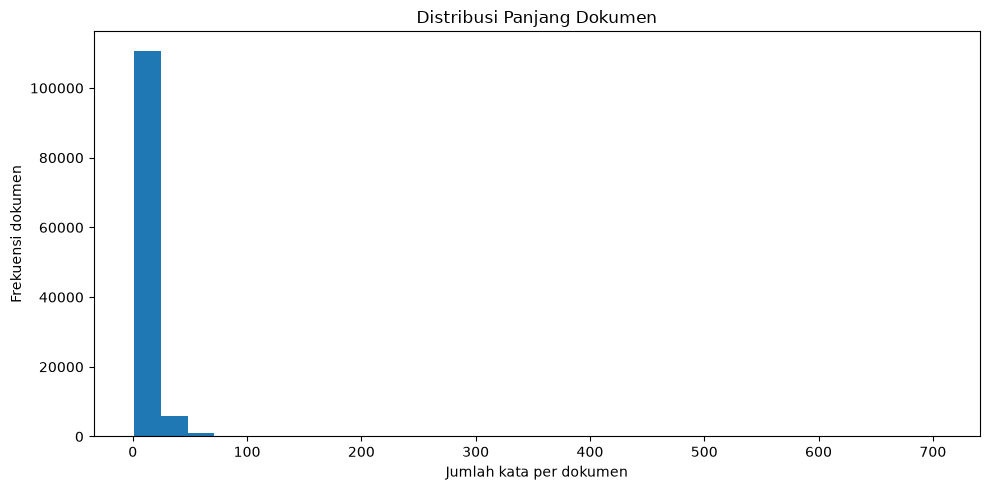

Visualisasi distribusi label tidak dibuat karena kolom label tidak terdeteksi pada dataset.


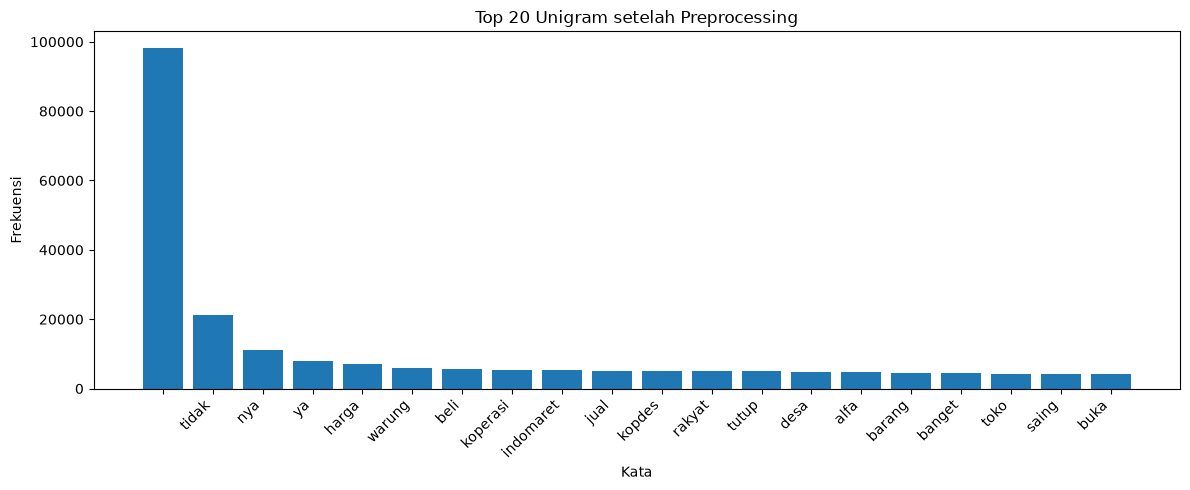

In [23]:
# 1. Distribusi panjang dokumen
plt.figure(figsize=(10, 5))
plt.hist(corpus["jumlah_kata"], bins=30)
plt.xlabel("Jumlah kata per dokumen")
plt.ylabel("Frekuensi dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.tight_layout()
plt.show()

# 2. Distribusi label, jika tersedia
if LABEL_COLUMN:
    label_counts = corpus[LABEL_COLUMN].fillna("Missing").astype(str).value_counts().head(30)
    plt.figure(figsize=(10, 5))
    label_counts.plot(kind="bar")
    plt.xlabel("Label")
    plt.ylabel("Jumlah dokumen")
    plt.title(f"Distribusi Label: {LABEL_COLUMN}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Visualisasi distribusi label tidak dibuat karena kolom label tidak terdeteksi pada dataset.")

# 3. Frekuensi unigram top 20
if not top_unigram.empty:
    plt.figure(figsize=(12, 5))
    plt.bar(top_unigram["Kata"], top_unigram["Frekuensi"])
    plt.xlabel("Kata")
    plt.ylabel("Frekuensi")
    plt.title("Top 20 Unigram setelah Preprocessing")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# 14. Analysis

In [24]:
analysis_columns = [TEXT_COLUMN, "clean_text", "normalized_text", "text_no_stopword", "processed_text"]
display(corpus[analysis_columns].head(10))

print("Ringkasan kualitas data:")
print("- Dokumen setelah teks kosong dan duplikat dikeluarkan:", len(corpus))
print("- Missing pada kolom teks sebelum cleaning:", int(df[TEXT_COLUMN].isna().sum()))
print("- Duplikat teks pada data awal:", int(df[TEXT_COLUMN].duplicated().sum()))
print("- Stemming Sastrawi aktif:", STEMMING_AVAILABLE)
print("- POS/dependency model aktif:", nlp is not None)


,comment,clean_text,normalized_text,text_no_stopword,processed_text
0,Beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m ?,beliau bilang untung nya 2 m
1,Makasih Mas,makasih mas,makasih mas,makasih mas,makasih mas
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m,gimana untung nya 2 m .. barang yang di jual ajh tidak ada 1 m,gimana untung nya 2 m .. barang jual ajh tidak 1 m,gimana untung nya 2 m barang jual ajh tidak 1 m
3,[Sticker] dibilang Makasih Mas udah 2M itu,sticker dibilang makasih mas udah 2m itu,sticker dibilang makasih mas sudah 2m itu,sticker dibilang makasih mas 2m,sticker bilang makasih mas 2m
4,😳😳😳,,,,
5,"Kalo niat membantu UMKM, harusnya koprasi merah putih dibuka dalam bentuk warehouse (gudang), bukan bentuk toko, jad...","kalo niat membantu umkm, harusnya koprasi merah putih dibuka dalam bentuk warehouse gudang , bukan bentuk toko, jadi...","kalau niat membantu umkm , harusnya koprasi merah putih dibuka dalam bentuk warehouse gudang , bukan bentuk toko , j...","niat membantu umkm , koprasi merah putih dibuka bentuk warehouse gudang , bukan bentuk toko , belanja umkm memiliki ...",niat bantu umkm koprasi merah putih buka bentuk warehouse gudang bukan bentuk toko belanja umkm milik usaha toko ...
6,sabar mbak paling 6 bulan dah tutup,sabar mbak paling 6 bulan dah tutup,sabar mbak paling 6 bulan sudah tutup,sabar mbak 6 tutup,sabar mbak 6 tutup
7,"kalo ternyata harga murah, saya harap bisa berjalan terus.","kalo ternyata harga murah, saya harap bisa berjalan terus.","kalau ternyata harga murah , saya harap bisa berjalan terus .","harga murah , harap berjalan .",harga murah harap jalan
8,"SAYA SETUJU BANG, soalnya saya punya warung 😔","saya setuju bang, soalnya saya punya warung","saya setuju bang , soalnya saya punya warung","setuju bang , warung",tuju bang warung
9,Ancen Dancuk 🥵🥵🥵,ancen dancuk,ancen dancuk,ancen dancuk,ancen dancuk


Ringkasan kualitas data:
- Dokumen setelah teks kosong dan duplikat dikeluarkan: 117814
- Missing pada kolom teks sebelum cleaning: 304
- Duplikat teks pada data awal: 102236
- Stemming Sastrawi aktif: True
- POS/dependency model aktif: True


### Pertanyaan Refleksi Modul 1

**1. Mengapa komputer tidak dapat langsung memahami teks mentah?**  
Teks mentah berupa rangkaian karakter yang memiliki variasi ejaan, struktur, konteks, dan ambiguitas. Komputer perlu mengubahnya menjadi unit dan representasi yang dapat dihitung sebelum pola bahasa dapat dianalisis.

**2. Apa perbedaan document, sentence, word, token, dan character?**  
Document adalah satu unit dokumen, misalnya satu komentar. Sentence adalah kalimat di dalam dokumen. Word adalah kata secara linguistik. Token adalah unit yang dihasilkan tokenizer dan bisa berupa kata, tanda baca, atau potongan lain. Character adalah karakter penyusun teks.

**3. Mengapa tokenization penting dalam NLP?**  
Tokenisasi membagi teks menjadi unit yang dapat dihitung untuk analisis frekuensi, preprocessing, n-gram, dan model bahasa. Kesalahan tokenisasi dapat memengaruhi semua tahap berikutnya.

**4. Apakah semua punctuation harus dihapus?**  
Tidak. Tanda titik dan tanda tanya membantu segmentasi kalimat, tanda seru dapat menunjukkan penekanan, sedangkan tanda baca dalam angka atau URL dapat memiliki fungsi khusus. Penghapusan harus mengikuti tujuan analisis.

**5. Apakah semua stopword harus dihapus?**  
Tidak. Kata seperti “tidak” dan “bukan” dapat membalik makna. Contohnya, “produk bagus” berbeda dengan “produk tidak bagus”, sehingga kata negasi dipertahankan dalam pipeline ini.

**6. Apa perbedaan stemming dan lemmatization?**  
Stemming memotong atau mengubah imbuhan dengan aturan morfologis sederhana untuk memperoleh bentuk dasar, sedangkan lemmatization menggunakan analisis bahasa untuk mencari lemma atau bentuk kamus yang sesuai konteks.

**7. Apa hubungan morphology dengan stemming?**  
Morfologi mempelajari struktur kata dan proses pembentukan kata, termasuk imbuhan. Stemming memanfaatkan pola morfologi untuk mengurangi variasi bentuk kata.

**8. Apa manfaat POS Tagging dalam NLP?**  
POS tagging memberi label kelas kata seperti nomina, verba, atau adjektiva. Informasi ini membantu analisis sintaksis, ekstraksi informasi, dan pemahaman struktur kalimat.

**9. Apa manfaat dependency parsing?**  
Dependency parsing memetakan hubungan antar-token, misalnya kata mana menjadi subjek, objek, atau bergantung pada predikat. Hasilnya membantu analisis struktur kalimat, tetapi tetap perlu diperiksa pada bahasa informal.

**10. Mengapa n-gram mengalami sparsity?**  
Semakin panjang urutan kata, semakin banyak kombinasi yang mungkin. Banyak kombinasi tidak muncul dalam corpus, sehingga estimasi probabilitas menjadi jarang dan model kesulitan menangani urutan baru.

**11. Apa perbedaan unigram, bigram, dan trigram?**  
Unigram menghitung satu token, bigram menghitung pasangan token berurutan, sedangkan trigram menghitung tiga token berurutan.

**12. Mengapa neural language model diperlukan setelah n-gram?**  
N-gram memiliki konteks terbatas dan sulit menangani urutan yang belum pernah muncul. Neural language model dapat mempelajari representasi kontekstual dan hubungan yang lebih luas, walaupun memerlukan komputasi serta evaluasi yang lebih kompleks.


## 15. Conclusion

Pipeline ini menyatukan eksplorasi corpus, pembersihan, segmentasi kalimat, tokenisasi kata dan karakter, normalisasi, stopword removal, stemming, analisis linguistik, n-gram, language model, dan visualisasi. Kualitas hasil bergantung pada karakter dataset dan keputusan preprocessing. Hasil otomatis harus dievaluasi dengan contoh nyata, khususnya untuk komentar informal Bahasa Indonesia.